# Tempo de jogo e desempenho acadêmico
**UNO – Universidade Comunitária da Região de Chapecó**
**Curso:** Sistemas de Informação | **Componente:** ABEX VI – Projeto Integrado III
**Grupo 00:** Alice Botton Dal Paz, Anthony Guilherme Cazuni da Silva, Gabriel Henrique Robette Ferri, João Vitor Canello
**Professor:** Mateus Henrique Zeiser

**Pergunta central:** Qual a relação entre o tempo dedicado a videogames e o desempenho acadêmico dos estudantes, e em que medida essa relação é explicada por fatores como tempo de estudo, sono, nível de estresse e grau de dependência do jogo?

In [1]:
# Dependências. Em uma máquina nova ou no Google Colab, descomente a linha abaixo.
# %pip install pandas numpy matplotlib seaborn kagglehub

## 1. Carregamento dos dados
Utilizamos a base pública "Gaming vs Academic Performance", disponível no Kaggle e baixada com a biblioteca `kagglehub`. Antes de qualquer alteração, salvamos uma cópia da base original na pasta `dados/`, que corresponde ao arquivo de base original da entrega.

In [2]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("dados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

# A base original está versionada no repositório: o notebook roda sem depender de download.
ARQUIVO = "dados/Base_Original_GrupoGamingvsAcademicPerformance.csv"

if not os.path.exists(ARQUIVO):
    # Alternativa (primeira execução, máquina nova ou Colab): baixar do Kaggle e salvar a cópia local.
    import kagglehub
    baixado = glob.glob(os.path.join(
        kagglehub.dataset_download("aiexplorer77/gaming-vs-academic-performance"), "*.csv"))[0]
    pd.read_csv(baixado).to_csv(ARQUIVO, index=False)
    print("Base baixada do Kaggle e salva em", ARQUIVO)

df_original = pd.read_csv(ARQUIVO)
print("Origem dos dados:", ARQUIVO)
print("Dimensões (linhas, colunas):", df_original.shape)
df_original.head()

Origem dos dados: dados/Base_Original_GrupoGamingvsAcademicPerformance.csv
Dimensões (linhas, colunas): (8000, 14)


,student_id,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades
0,1,22,Male,7.23,8.78,6.96,91.44,FPS,3.25,9.36,235.84,14.69,Low,86.459555
1,2,19,Male,0.07,8.72,7.63,63.63,Casual,1.02,3.21,328.71,2.47,Medium,98.230000
2,3,23,Female,1.73,9.56,4.40,83.26,Casual,3.46,5.56,313.61,4.73,High,90.560000
3,4,20,Female,6.62,1.68,7.83,75.04,RPG,1.46,11.78,241.84,14.54,Low,32.670000
4,5,22,Female,5.36,5.83,5.55,65.57,FPS,1.01,8.23,249.31,12.48,Low,58.710000


## 2. Reconhecimento da base
Verificamos os tipos de cada variável e as estatísticas descritivas (média, desvio padrão, mínimo, quartis e máximo) para entender a escala dos dados e identificar possíveis inconsistências.

In [3]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        8000 non-null   int64  
 1   age               8000 non-null   int64  
 2   gender            8000 non-null   str    
 3   gaming_hours      8000 non-null   float64
 4   study_hours       8000 non-null   float64
 5   sleep_hours       8000 non-null   float64
 6   attendance        8000 non-null   float64
 7   gaming_genre      8000 non-null   str    
 8   social_activity   8000 non-null   float64
 9   device_usage      8000 non-null   float64
 10  reaction_time_ms  8000 non-null   float64
 11  addiction_score   8000 non-null   float64
 12  stress_level      8000 non-null   str    
 13  grades            8000 non-null   float64
dtypes: float64(9), int64(2), str(3)
memory usage: 875.1 KB


In [4]:
display(df_original.describe().T.round(2))
display(df_original.describe(exclude="number").T)    

,count,mean,std,min,25%,50%,75%,max
student_id,8000.0,4000.50,2309.55,1.00,2000.75,4000.50,6000.25,8000.00
age,8000.0,19.98,2.59,16.00,18.00,20.00,22.00,24.00
gaming_hours,8000.0,4.09,2.31,0.00,2.13,4.13,6.06,8.00
study_hours,8000.0,5.46,2.58,1.00,3.24,5.46,7.66,10.00
sleep_hours,8000.0,6.49,1.44,4.00,5.24,6.50,7.73,9.00
attendance,8000.0,79.89,11.58,60.00,69.78,79.69,90.10,100.00
social_activity,8000.0,2.51,1.44,0.00,1.29,2.50,3.76,5.00
device_usage,8000.0,7.59,2.71,1.10,5.56,7.61,9.60,13.95
reaction_time_ms,8000.0,271.11,29.44,183.26,247.16,270.48,294.69,347.87
addiction_score,8000.0,9.91,5.04,-4.51,5.92,10.00,13.86,23.16


,count,unique,top,freq
gender,8000,3,Male,3904
gaming_genre,8000,3,FPS,3187
stress_level,8000,3,Medium,4247


**Observações:** A base possui 8.000 registros e 14 variáveis, sem valores ausentes (todas as colunas têm 8.000 valores preenchidos). A idade dos estudantes varia de 16 a 24 anos (média de 19,98), com distribuição equilibrada entre os gêneros masculino (49%) e feminino (48%), além de 4% classificados como "Other". As horas de jogo variam de 0 a 8 por dia, com média de 4,09h, enquanto as horas de estudo variam de 1 a 10 (média de 5,46h) e as de sono de 4 a 9 (média de 6,49h). O gênero de jogo mais frequente é FPS (3.187 estudantes) e o nível de estresse mais comum é Medium (4.247).

Foram identificadas duas inconsistências: a nota (`grades`) tem média 66,18 e máximo 118,63, ou seja, existem notas acima de 100; e o `addiction_score` apresenta valor mínimo de -4,51, o que não faz sentido para um escore de dependência. Os valores numéricos também apresentam muitas casas decimais, e a própria descrição do dataset no Kaggle informa que os dados são simulados, o que deve ser considerado na interpretação dos resultados.

## 3. Qualidade dos dados: valores ausentes e duplicados
Verificamos se há valores ausentes e registros duplicados. Caso existam, os ausentes numéricos são preenchidos pela mediana (medida robusta a valores extremos), os categóricos pela moda, e as linhas duplicadas são removidas.

In [5]:
df = df_original.copy()

print("Valores ausentes por coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("student_id repetidos:", df["student_id"].duplicated().sum())

df = df.drop_duplicates()

num_cols = df.select_dtypes(include="number").columns.drop("student_id", errors="ignore")
cat_cols = df.select_dtypes(exclude="number").columns.drop("student_id", errors="ignore")

for c in num_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])

print("\nDimensões após o tratamento:", df.shape)

Valores ausentes por coluna:
student_id          0
age                 0
gender              0
gaming_hours        0
study_hours         0
sleep_hours         0
attendance          0
gaming_genre        0
social_activity     0
device_usage        0
reaction_time_ms    0
addiction_score     0
stress_level        0
grades              0
dtype: int64

Linhas duplicadas: 0
student_id repetidos: 0

Dimensões após o tratamento: (8000, 14)


**Resultado:** Não foram encontrados valores ausentes (todas as 14 variáveis possuem 8.000 registros preenchidos) nem linhas duplicadas, e cada `student_id` aparece uma única vez na base. Portanto, nenhum tratamento foi necessário nesta etapa.

## 4. Valores fora da faixa esperada
Verificamos se as variáveis respeitam limites lógicos: notas e frequência entre 0 e 100, horas entre 0 e 24, e a soma de horas de jogo, estudo e sono não ultrapassando 24h por dia.

In [6]:
faixas = {"grades": (0, 100), "attendance": (0, 100),
          "gaming_hours": (0, 24), "study_hours": (0, 24), "sleep_hours": (0, 24)}

for col, (mn, mx) in faixas.items():
    fora = ((df[col] < mn) | (df[col] > mx)).sum()
    print(f"{col}: {fora} valores fora de [{mn}, {mx}]")

soma = df["gaming_hours"] + df["study_hours"] + df["sleep_hours"]
print("\nRegistros com jogo + estudo + sono > 24h:", (soma > 24).sum())

grades: 134 valores fora de [0, 100]
attendance: 0 valores fora de [0, 100]
gaming_hours: 0 valores fora de [0, 24]
study_hours: 0 valores fora de [0, 24]
sleep_hours: 0 valores fora de [0, 24]

Registros com jogo + estudo + sono > 24h: 98


In [7]:
n_acima = (df["grades"] > 100).sum()
print(f"Notas acima de 100: {n_acima} ({n_acima / len(df):.1%} da base)")

df["grades"] = df["grades"].clip(lower=0, upper=100)
print("Nota máxima após o tratamento:", df["grades"].max())
n_neg = (df["addiction_score"] < 0).sum()
print(f"\naddiction_score negativos: {n_neg} ({n_neg / len(df):.1%} da base)")

df["addiction_score"] = df["addiction_score"].clip(lower=0)
print("addiction_score mínimo após o tratamento:", df["addiction_score"].min())
soma = df["gaming_hours"] + df["study_hours"] + df["sleep_hours"]
n_24h = (soma > 24).sum()
print(f"\nRegistros com mais de 24h somadas: {n_24h} ({n_24h / len(df):.1%} da base)")

df = df[soma <= 24].reset_index(drop=True)
print("Dimensões após a remoção:", df.shape)

Notas acima de 100: 134 (1.7% da base)
Nota máxima após o tratamento: 100.0

addiction_score negativos: 107 (1.3% da base)
addiction_score mínimo após o tratamento: 0.0

Registros com mais de 24h somadas: 98 (1.2% da base)
Dimensões após a remoção: (7902, 14)


**Decisão:** Foram encontradas 134 notas acima de 100 (1,7% da base). Optamos por limitá-las ao valor máximo (100) em vez de remover os registros, para preservar o tamanho da amostra e as demais informações desses estudantes. Como a proporção é pequena, o impacto na distribuição das notas é mínimo.

Também foram encontrados 107 valores negativos em `addiction_score` (1,3% da base), o que é inconsistente para um escore de dependência. Seguindo o mesmo critério, esses valores foram limitados a 0, preservando os registros.

Por fim, 98 registros (1,2% da base) apresentaram soma de horas de jogo, estudo e sono superior a 24 horas por dia, o que é fisicamente impossível. Nesse caso, não é possível identificar qual das três variáveis está incorreta, então limitar valores não resolveria o problema. Por isso, optamos por remover esses registros. A base final utilizada nas análises tem 7.902 registros.

## 5. Transformações
- **Arredondamento:** valores numéricos arredondados para 2 casas decimais, devido à precisão irreal da base.
- **Codificação ordinal:** `stress_level` convertida para escala numérica (Low = 1, Medium = 2, High = 3), pois existe ordem natural entre os níveis.
- **Exclusão:** `student_id` removida por ser apenas um identificador, sem valor analítico.
- As variáveis nominais (`gender` e `gaming_genre`) não têm ordem entre categorias, por isso serão convertidas por one-hot encoding apenas na etapa de regressão.

Ao final, a base pré-processada é salva em `dados/`.

In [8]:
df[num_cols] = df[num_cols].round(2)

df["stress_level_ord"] = df["stress_level"].map({"Low": 1, "Medium": 2, "High": 3})
print("Valores não mapeados em stress_level:", df["stress_level_ord"].isna().sum())

df = df.drop(columns=["student_id"])

ARQUIVO_TRATADO = "dados/Base_PreProcessada_GrupoGamingvsAcademicPerformance.csv"
df.to_csv(ARQUIVO_TRATADO, index=False)
print("Base pré-processada:", df.shape)
df.head()

Valores não mapeados em stress_level: 0


Base pré-processada: (7902, 14)


,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades,stress_level_ord
0,22,Male,7.23,8.78,6.96,91.44,FPS,3.25,9.36,235.84,14.69,Low,86.46,1
1,19,Male,0.07,8.72,7.63,63.63,Casual,1.02,3.21,328.71,2.47,Medium,98.23,2
2,23,Female,1.73,9.56,4.40,83.26,Casual,3.46,5.56,313.61,4.73,High,90.56,3
3,20,Female,6.62,1.68,7.83,75.04,RPG,1.46,11.78,241.84,14.54,Low,32.67,1
4,22,Female,5.36,5.83,5.55,65.57,FPS,1.01,8.23,249.31,12.48,Low,58.71,1


## 6. Efeito da preparação sobre os dados

Antes de interpretar qualquer resultado, é preciso medir o que o **próprio tratamento** alterou. Duas decisões da
seção 4 exigem avaliação:

- **Limitar as notas a 100 cria valores que não existiam:** as 134 notas acima de 100 passaram todas a valer
  exatamente 100, engrossando um pico que já existia na base.
- **Remover os 98 registros com mais de 24 horas diárias não é uma remoção aleatória:** por construção, só caem nessa
  regra estudantes com horas altas nas três variáveis somadas, e esse perfil pode estar associado à nota.

In [9]:
# Reconstrução das etapas, a partir da base original, para medir o efeito de cada uma.
etapa0 = df_original.drop_duplicates().copy()                      # base original
etapa1 = etapa0.copy()
etapa1["grades"] = etapa1["grades"].clip(0, 100)                   # após limitar as notas
etapa1["addiction_score"] = etapa1["addiction_score"].clip(lower=0)
etapa1["nota_foi_limitada"] = etapa0["grades"] > 100               # marca quem teve a nota alterada
horas_dia = etapa1["gaming_hours"] + etapa1["study_hours"] + etapa1["sleep_hours"]
removidas, etapa2 = etapa1[horas_dia > 24], etapa1[horas_dia <= 24]  # após remover os dias impossíveis

def descritivas(d, colunas):
    r = d[colunas].describe().T[["min", "25%", "50%", "mean", "75%", "max", "std"]]
    r.columns = ["mín", "Q1", "mediana", "média", "Q3", "máx", "desvio padrão"]
    r["IQR"] = (r["Q3"] - r["Q1"]).round(2)
    return r.round(2)

COLS_TAB = ["gaming_hours", "study_hours", "sleep_hours", "attendance", "addiction_score", "reaction_time_ms", "grades"]
print("Estatísticas descritivas nas duas bases (medidas de centro, dispersão e extremos):")
display(pd.concat({f"base original (n = {len(etapa0):,})".replace(",", "."): descritivas(etapa0, COLS_TAB),
                   f"base pré-processada (n = {len(etapa2):,})".replace(",", "."): descritivas(etapa2, COLS_TAB)}))

Estatísticas descritivas nas duas bases (medidas de centro, dispersão e extremos):


mín      Q1  mediana  \
base original (n = 8.000)       gaming_hours        0.00    2.13     4.13   
                                study_hours         1.00    3.24     5.46   
                                sleep_hours         4.00    5.24     6.50   
                                attendance         60.00   69.78    79.69   
                                addiction_score    -4.51    5.92    10.00   
                                reaction_time_ms  183.26  247.16   270.48   
                                grades              0.00   49.88    67.07   
base pré-processada (n = 7.902) gaming_hours        0.00    2.09     4.09   
                                study_hours         1.00    3.20     5.39   
                                sleep_hours         4.00    5.23     6.47   
                                attendance         60.00   69.77    79.69   
                                addiction_score     0.00    5.88     9.90   
                                reaction_time_ms  183.26  247.97   271.13   
                                grades              0.00   49.60    66.68   

                                                   média      Q3     máx  \
base original (n = 8.000)       gaming_hours        4.09    6.06    8.00   
                                study_hours         5.46    7.66   10.00   
                                sleep_hours         6.49    7.73    9.00   
                                attendance         79.89   90.10  100.00   
                                addiction_score     9.91   13.86   23.16   
                                reaction_time_ms  271.11  294.69  347.87   
                                grades             66.18   83.99  118.63   
base pré-processada (n = 7.902) gaming_hours        4.05    5.99    8.00   
                                study_hours         5.41    7.57   10.00   
                                sleep_hours         6.47    7.69    9.00   
                                attendance         79.88   90.10  100.00   
                                addiction_score     9.84   13.72   23.01   
                                reaction_time_ms  271.58  295.07  347.87   
                                grades             65.86   83.78  100.00   

                                                  desvio padrão    IQR  
base original (n = 8.000)       gaming_hours               2.31   3.93  
                                study_hours                2.58   4.42  
                                sleep_hours                1.44   2.49  
                                attendance                11.58  20.32  
                                addiction_score            5.04   7.94  
                                reaction_time_ms          29.44  47.53  
                                grades                    22.42  34.11  
base pré-processada (n = 7.902) gaming_hours               2.29   3.90  
                                study_hours                2.55   4.37  
                                sleep_hours                1.44   2.46  
                                attendance                11.59  20.33  
                                addiction_score            4.98   7.84  
                                reaction_time_ms          29.29  47.10  
                                grades                    22.28  34.19

In [10]:
# 6.1 De onde vem o pico em 100?
ja_eram_100 = int((etapa0["grades"] == 100).sum())
viraram_100 = int((etapa0["grades"] > 100).sum())
pico_final = int((etapa2["grades"] == 100).sum())
perdidos = ja_eram_100 + viraram_100 - pico_final

print(f"Notas exatamente 100 na base original ......... {ja_eram_100}")
print(f"Notas acima de 100, limitadas a 100 ........... {viraram_100}")
print(f"Removidas depois (mais de 24h no dia) ......... {perdidos}")
print(f"Pico em 100 na base pré-processada ............ {pico_final}")
print(f"-> {viraram_100 / pico_final:.1%} do pico em 100 foi CRIADO pelo tratamento.")
print(f"-> Estudantes com nota 100: {ja_eram_100 / len(etapa0):.1%} da base original "
      f"-> {pico_final / len(etapa2):.1%} da base tratada.")

Notas exatamente 100 na base original ......... 439
Notas acima de 100, limitadas a 100 ........... 134
Removidas depois (mais de 24h no dia) ......... 4
Pico em 100 na base pré-processada ............ 569
-> 23.6% do pico em 100 foi CRIADO pelo tratamento.
-> Estudantes com nota 100: 5.5% da base original -> 7.2% da base tratada.


In [11]:
# 6.2 As 98 linhas removidas são diferentes das que ficaram?
perfil = pd.DataFrame({
    "removidas (n = 98)": removidas[COLS_TAB].mean(),
    "mantidas (n = 7.902)": etapa2[COLS_TAB].mean(),
})
perfil["diferença"] = perfil.iloc[:, 0] - perfil.iloc[:, 1]
display(perfil.round(2))

print(f"Nota média: removidas {removidas['grades'].mean():.2f} x mantidas {etapa2['grades'].mean():.2f}")
print(f"Com nota >= 80: removidas {(removidas['grades'] >= 80).mean():.1%} x mantidas {(etapa2['grades'] >= 80).mean():.1%}")
print("\nNível de estresse das removidas (%):")
display((100 * removidas["stress_level"].value_counts(normalize=True)).round(1).to_frame("% das removidas"))
print("Efeito sobre a média do grupo de estresse Low:")
print(f"  antes de remover: {etapa1.loc[etapa1.stress_level == 'Low', 'grades'].mean():.2f} "
      f"(n = {(etapa1.stress_level == 'Low').sum()})")
print(f"  depois de remover: {etapa2.loc[etapa2.stress_level == 'Low', 'grades'].mean():.2f} "
      f"(n = {(etapa2.stress_level == 'Low').sum()})")

,removidas (n = 98),mantidas (n = 7.902),diferença
gaming_hours,7.27,4.05,3.22
study_hours,9.29,5.41,3.88
sleep_hours,8.26,6.47,1.79
attendance,80.07,79.88,0.19
addiction_score,16.42,9.84,6.58
reaction_time_ms,232.91,271.58,-38.67
grades,83.64,65.86,17.78


Nota média: removidas 83.64 x mantidas 65.86
Com nota >= 80: removidas 64.3% x mantidas 30.2%

Nível de estresse das removidas (%):


,% das removidas
stress_level,
Low,100.0


Efeito sobre a média do grupo de estresse Low:
  antes de remover: 50.50 (n = 2743)
  depois de remover: 49.27 (n = 2645)


In [12]:
# 6.3 As conclusões mudariam com outras decisões de limpeza? (análise de sensibilidade)
ord_estresse = {"Low": 1, "Medium": 2, "High": 3}

def cenario(d):
    s = d["stress_level"].map(ord_estresse)
    medias = d.groupby("stress_level")["grades"].mean()
    return {"n": len(d), "nota média": d["grades"].mean(), "desvio padrão": d["grades"].std(),
            "r jogo": d["gaming_hours"].corr(d["grades"]), "r estudo": d["study_hours"].corr(d["grades"]),
            "r estresse": s.corr(d["grades"]), "r tempo de reação": d["reaction_time_ms"].corr(d["grades"]),
            "amplitude estresse": medias.max() - medias.min()}

cenarios = {
    "A. adotado (limita 134, remove 98)": etapa2,
    "B. remove as 134 em vez de limitar": etapa1[(horas_dia <= 24) & (etapa0["grades"] <= 100)],
    "C. limita 134, mantém as 98": etapa1,
    "D. base original, sem tratamento": etapa0,
}
display(pd.DataFrame({k: cenario(d) for k, d in cenarios.items()}).T.round(2))

,n,nota média,desvio padrão,r jogo,r estudo,r estresse,r tempo de reação,amplitude estresse
"A. adotado (limita 134, remove 98)",7902.0,65.86,22.28,-0.57,0.73,0.52,0.54,31.61
B. remove as 134 em vez de limitar,7772.0,65.29,22.02,-0.57,0.72,0.53,0.54,31.79
"C. limita 134, mantém as 98",8000.0,66.08,22.25,-0.55,0.73,0.50,0.52,30.38
"D. base original, sem tratamento",8000.0,66.18,22.42,-0.55,0.73,0.50,0.52,30.45


**Observações:** o tratamento é defensável, mas não é neutro, e três efeitos precisam ficar registrados.

**1. Um quarto do pico em 100 é artefato nosso.** Dos 569 estudantes com nota 100 na base tratada, **435 já tinham
essa nota** e **134 (23,6%) foram criados ao limitarmos as notas acima de 100**. A proporção de notas máximas sobe de
5,5% para 7,2% da base. O "efeito teto" que aparece no histograma é, em boa parte, consequência da decisão de limitar
em vez de remover. A alternativa — remover as 134 — está avaliada em 6.3.

**2. A remoção das 98 linhas é seletiva, e na mesma direção do achado contraintuitivo.** Os estudantes removidos não
são um recorte aleatório: tinham nota média **83,64** contra 65,86 dos mantidos (17,8 pontos a mais), 64,3% deles com
nota igual ou superior a 80, contra 30,2% dos mantidos. Isso é esperado, porque a regra só captura quem tem horas
altas nas três variáveis, inclusive estudo (9,29 h contra 5,41 h). O ponto delicado é outro: **os 98 removidos eram
100% do grupo de estresse Low**, justamente o grupo de menor nota média. Removê-los baixou a média desse grupo de
**50,50 para 49,27** e aumentou a amplitude entre estresse alto e baixo de 30,38 para 31,61 pontos. Ou seja, nosso
próprio tratamento **amplificou em 1,2 ponto** o resultado contraintuitivo que a seção 10 depois desmonta.

**3. As conclusões não dependem dessas escolhas.** A análise de sensibilidade compara quatro cenários. As correlações
principais variam pouco: as horas de jogo ficam entre −0,55 e −0,57, as de estudo entre 0,72 e 0,73, e a amplitude do
estresse entre 30,4 e 31,8 pontos. Nenhuma conclusão do trabalho se inverte em nenhum cenário. Mantemos a decisão
original (limitar as notas e remover os dias impossíveis), agora com o efeito de cada escolha documentado.

## 7. Análise Exploratória: Distribuições
Histogramas e boxplots das principais variáveis numéricas, e gráficos de barras das variáveis categóricas, para descrever o perfil dos estudantes.

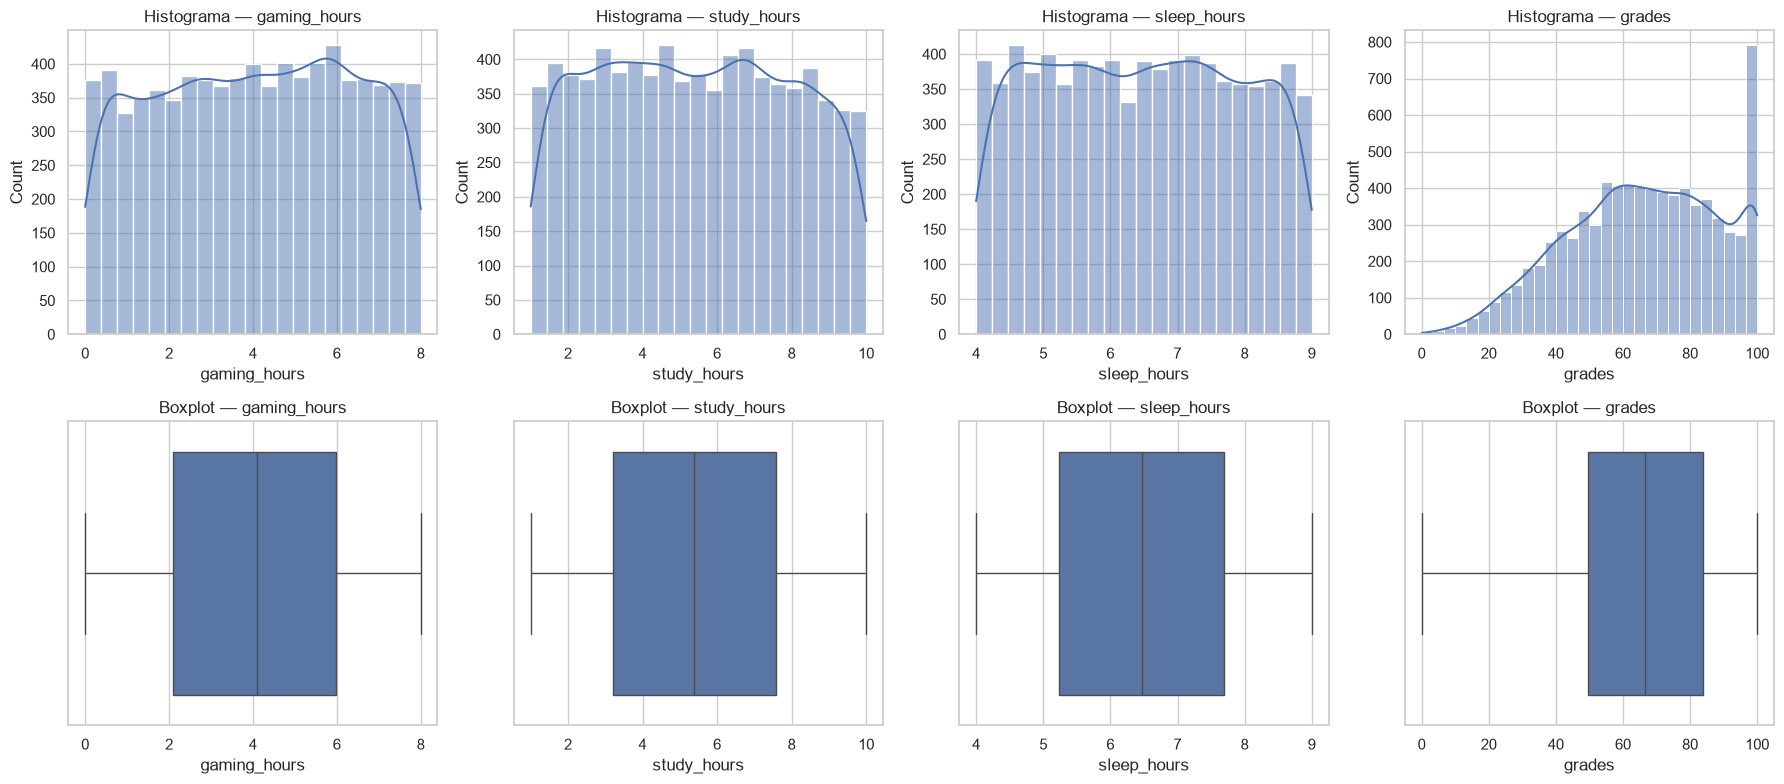

In [13]:
vars_principais = ["gaming_hours", "study_hours", "sleep_hours", "grades"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(vars_principais):
    sns.histplot(df[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Histograma — {col}")
    sns.boxplot(x=df[col], ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.savefig("figuras/fig01_distribuicoes.png", dpi=150)
plt.show()

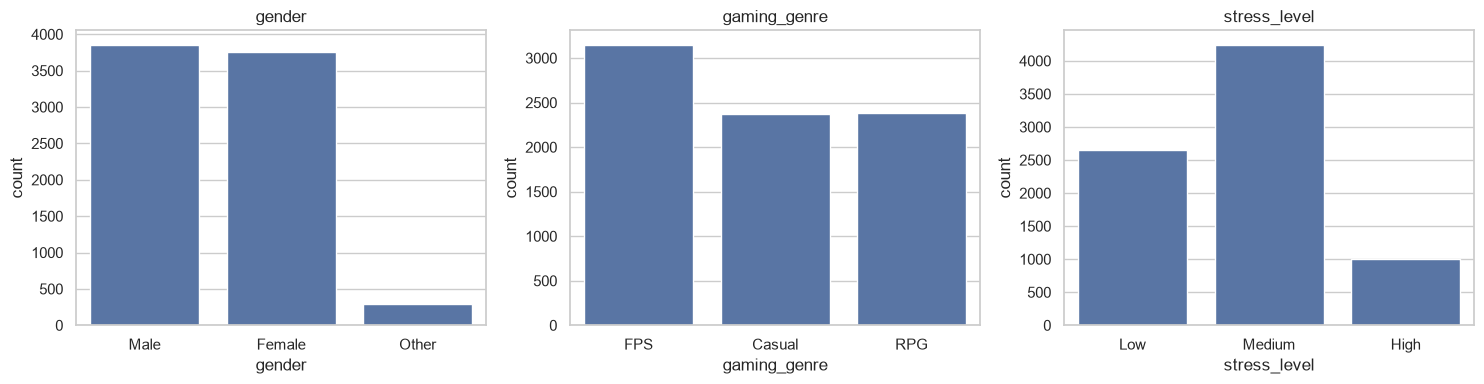

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["gender", "gaming_genre", "stress_level"]):
    ordem = ["Low", "Medium", "High"] if col == "stress_level" else None
    sns.countplot(data=df, x=col, order=ordem, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("figuras/fig02_categoricas.png", dpi=150)
plt.show()

**Observações:** As horas de jogo (0 a 8h), de estudo (1 a 10h) e de sono (4 a 9h) apresentam distribuição aproximadamente uniforme, sem concentração em faixas específicas, e os boxplots não indicam outliers nessas variáveis. Esse padrão uniforme é mais um indício de dados simulados, já que hábitos reais tendem a se concentrar em torno de valores típicos.

As notas se concentram entre 50 e 85 (mediana 66,68) e apresentam um pico acentuado em 100. Como mostrado na seção 6, esse pico **não é só um efeito teto da base**: dos 569 estudantes com nota 100, **435 já tinham essa nota na base original e 134 (23,6%) foram criados pelo nosso tratamento**, ao limitarmos as notas acima de 100. Quase um quarto do pico é, portanto, artefato da preparação, e não característica dos dados.

Quanto às variáveis categóricas, os gêneros masculino e feminino estão equilibrados, enquanto a categoria "Other" é bem menor (cerca de 4%). Entre os gêneros de jogo, FPS é o mais frequente, e Casual e RPG têm quantidades semelhantes. No nível de estresse há desequilíbrio: Medium concentra a maior parte dos estudantes, seguido de Low, enquanto High é o grupo menos numeroso. Isso deve ser considerado nas comparações entre grupos.

## 8. Análise Exploratória: Correlações
Matriz de correlação de Pearson entre as variáveis numéricas, representada em mapa de calor, e ranking das variáveis mais associadas à nota.

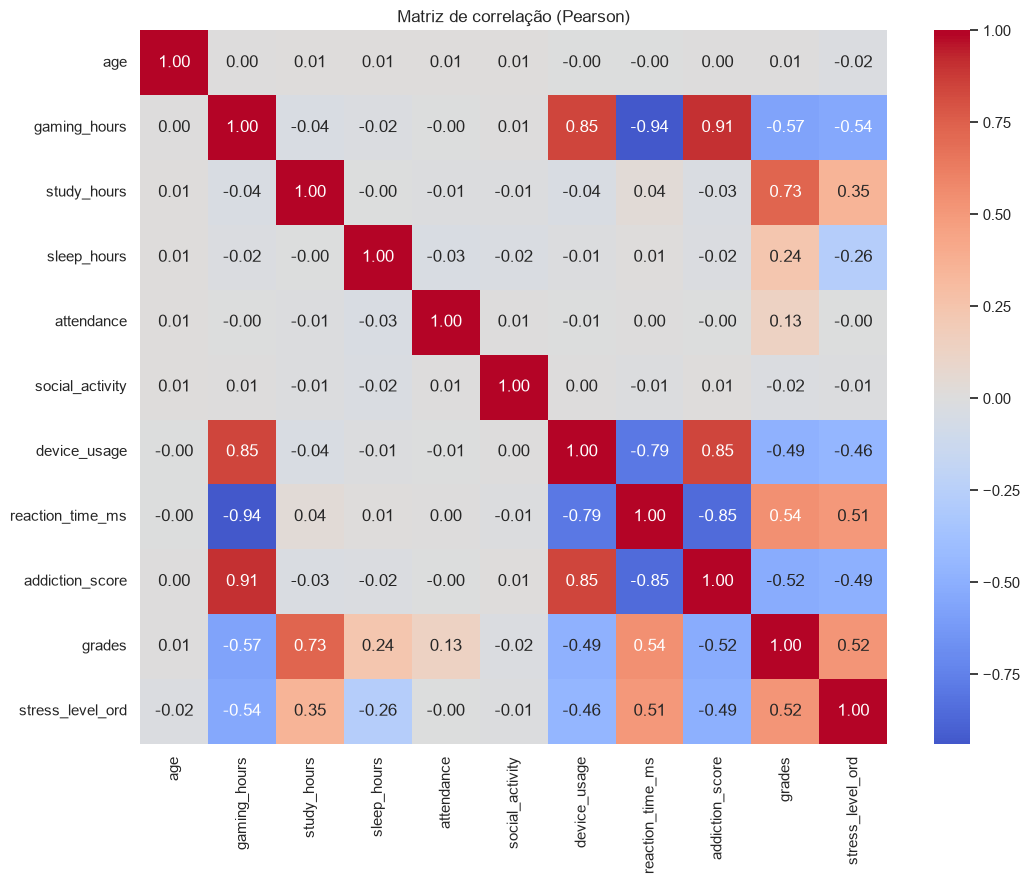

In [15]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação (Pearson)")
plt.tight_layout()
plt.savefig("figuras/fig03_correlacao.png", dpi=150)
plt.show()

In [16]:
print("Correlação de cada variável com a nota:")
print(corr["grades"].drop("grades").sort_values().round(3))
print("\nCorrelação jogo × sono:", round(corr.loc["gaming_hours", "sleep_hours"], 3))

Correlação de cada variável com a nota:
gaming_hours       -0.575
addiction_score    -0.518
device_usage       -0.490
social_activity    -0.020
age                 0.008
attendance          0.130
sleep_hours         0.241
stress_level_ord    0.518
reaction_time_ms    0.539
study_hours         0.731
Name: grades, dtype: float64

Correlação jogo × sono: -0.018


**Observações:** A variável mais associada à nota é o tempo de estudo, com correlação positiva forte (r = 0,731). As horas de jogo apresentam correlação negativa moderada com a nota (r = −0,575), acompanhadas do escore de dependência (r = −0,518) e do uso de dispositivos (r = −0,490), ambos também negativos.

A correlação entre horas de jogo e horas de sono é praticamente nula (r = −0,018), o que indica que a hipótese de mediação pelo sono não se sustenta: o sono tem alguma associação positiva com a nota (r = 0,241), mas não varia conforme o tempo de jogo.

**Atenção à redundância entre as variáveis.** A matriz mostra que `gaming_hours`, `device_usage`, `addiction_score` e `reaction_time_ms` são fortemente correlacionadas **entre si**: jogo × tempo de reação = −0,94, jogo × dependência = 0,91, jogo × uso de dispositivos = 0,85. Essas quatro colunas não são quatro fatores distintos, e sim quatro medidas do mesmo comportamento. Tratá-las como fatores separados — e colocá-las juntas em uma regressão — produziria coeficientes instáveis e uma contagem inflada de "fatores associados à nota". A avaliação formal dessa redundância está na seção 10.

Dois resultados chamam atenção: o nível de estresse tem correlação positiva com a nota (r = 0,518) e o tempo de reação também (r = 0,539). **Essas correlações são brutas**, isto é, não controlam nada. A seção 10 mostra que as duas praticamente desaparecem quando se consideram, ao mesmo tempo, as horas de jogo e de estudo.

Lembrando que correlação indica associação, e não relação de causa e efeito.

## 9. Análise Exploratória — Relações com a nota
Gráficos de dispersão com linha de tendência (amostra de 2.000 registros, para evitar sobreposição excessiva de pontos) e comparação da nota entre grupos de estresse e gênero de jogo.

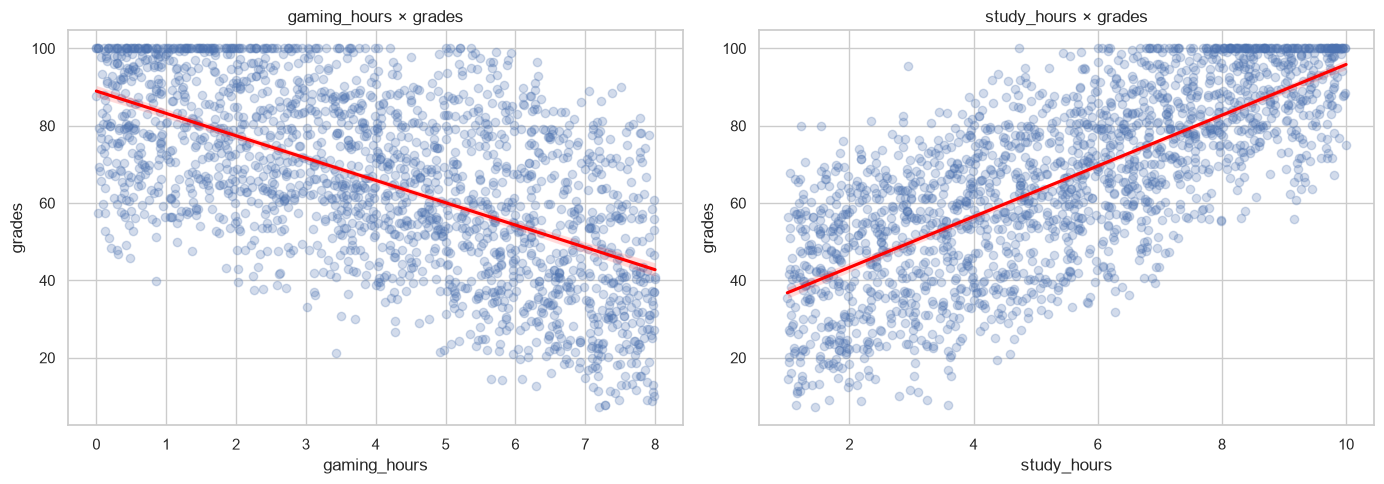

In [17]:
amostra = df.sample(2000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x in zip(axes, ["gaming_hours", "study_hours"]):
    sns.regplot(data=amostra, x=x, y="grades", ax=ax,
                scatter_kws={"alpha": 0.25}, line_kws={"color": "red"})
    ax.set_title(f"{x} × grades")
plt.tight_layout()
plt.savefig("figuras/fig04_dispersao.png", dpi=150)
plt.show()

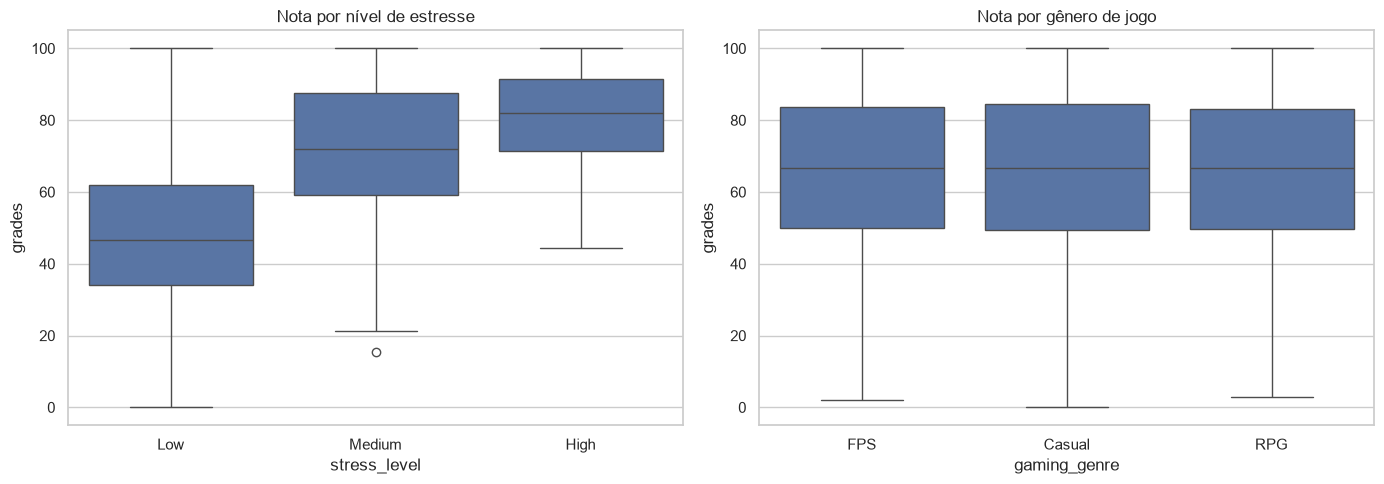

,mean,median,count
stress_level,,,
High,80.89,82.05,1010
Low,49.27,46.54,2645
Medium,72.62,72.08,4247


,mean,median,count
gaming_genre,,,
Casual,66.05,66.78,2372
FPS,65.87,66.56,3152
RPG,65.67,66.79,2378


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="stress_level", y="grades", order=["Low", "Medium", "High"], ax=axes[0])
axes[0].set_title("Nota por nível de estresse")
sns.boxplot(data=df, x="gaming_genre", y="grades", ax=axes[1])
axes[1].set_title("Nota por gênero de jogo")
plt.tight_layout()
plt.savefig("figuras/fig05_nota_por_grupo.png", dpi=150)
plt.show()

display(df.groupby("stress_level")["grades"].agg(["mean", "median", "count"]).round(2))
display(df.groupby("gaming_genre")["grades"].agg(["mean", "median", "count"]).round(2))

**Observações:** Os gráficos de dispersão confirmam as tendências observadas na matriz de correlação: a nota tende a cair à medida que aumentam as horas de jogo e a subir com mais horas de estudo. A relação é aproximadamente linear, mas com grande dispersão dos pontos, o que mostra que nenhuma variável sozinha explica a nota. Também é visível a concentração de estudantes na nota 100, lembrando que um quarto desse pico foi criado pelo tratamento (seção 6).

Na comparação por grupos, a nota aumenta com o nível de estresse: a média é de 49,27 no grupo Low, 72,62 no Medium e 80,89 no High, uma diferença de mais de 30 pontos entre os extremos. Esse contraste **não se sustenta quando se controla o tempo de jogo e de estudo** (seção 10): ele existe porque os grupos de estresse têm rotinas muito diferentes — o grupo High estuda em média 8,45 h por dia e o grupo Low, 4,83 h. Já entre os gêneros de jogo não há diferença relevante: as médias são de 66,05 para Casual, 65,87 para FPS e 65,67 para RPG, com medianas e dispersões praticamente iguais. Isso sugere que o tipo de jogo não se relaciona com o desempenho, e sim a quantidade de tempo jogado.

## 10. Controle por jogo e estudo: o que resta das associações?

As correlações das seções 7 a 9 são **brutas**: cada uma olha para uma variável de cada vez e ignora todas as outras.
Duas delas ficaram em aberto — o estresse e o tempo de reação se associam **positivamente** à nota, o que é
contraintuitivo — e três variáveis (dependência, uso de dispositivos e tempo de reação) são fortemente
correlacionadas com as horas de jogo.

Esta seção resolve as duas questões com três verificações, todas sobre a base tratada:

1. **Correlação parcial:** a correlação entre cada variável e a nota **depois de descontar** o que as horas de jogo e
   de estudo já explicam das duas (resíduo contra resíduo).
2. **Ganho de R²:** quanto cada variável acrescenta a um modelo que já contém jogo e estudo.
3. **Fator de inflação da variância (VIF):** quanto cada variável é previsível a partir das demais, que é a medida
   usual de redundância em regressão (O'BRIEN, 2007).

In [19]:
def residuo(y, controles):
    """Resíduo de y após regredir nas variáveis de controle (com intercepto)."""
    X = np.column_stack([np.ones(len(controles))] + [controles[c].values for c in controles.columns])
    beta, *_ = np.linalg.lstsq(X, y.values, rcond=None)
    return y.values - X @ beta

CONTROLES = ["gaming_hours", "study_hours"]
candidatas = ["stress_level_ord", "reaction_time_ms", "addiction_score", "device_usage",
              "sleep_hours", "attendance", "social_activity", "age"]

ctrl = df[CONTROLES]
res_nota = residuo(df["grades"], ctrl)

parciais = pd.DataFrame({
    "r bruto": {v: df[v].corr(df["grades"]) for v in candidatas},
    "r parcial": {v: np.corrcoef(residuo(df[v], ctrl), res_nota)[0, 1] for v in candidatas},
})
parciais["o que sobra"] = (parciais["r parcial"].abs() / parciais["r bruto"].abs()).round(2)
display(parciais.round(3))

,r bruto,r parcial,o que sobra
stress_level_ord,0.518,-0.098,0.19
reaction_time_ms,0.539,-0.013,0.02
addiction_score,-0.518,-0.001,0.00
device_usage,-0.490,-0.001,0.00
sleep_hours,0.241,0.576,2.39
attendance,0.130,0.337,2.59
social_activity,-0.020,-0.019,0.96
age,0.008,0.004,0.52


In [20]:
def r2(colunas):
    """R² de uma regressão linear da nota nas colunas indicadas."""
    X = np.column_stack([np.ones(len(df))] + [df[c].values for c in colunas])
    beta, *_ = np.linalg.lstsq(X, df["grades"].values, rcond=None)
    erro = df["grades"].values - X @ beta
    return 1 - (erro ** 2).sum() / ((df["grades"].values - df["grades"].mean()) ** 2).sum()

r2_base = r2(CONTROLES)
ganhos = pd.DataFrame({"R² com jogo + estudo + esta variável": {v: r2(CONTROLES + [v]) for v in candidatas}})
ganhos["ganho de R²"] = ganhos.iloc[:, 0] - r2_base
print(f"R² apenas com horas de jogo e de estudo: {r2_base:.4f}")
display(ganhos.sort_values("ganho de R²", ascending=False).round(4))

R² apenas com horas de jogo e de estudo: 0.8358


,R² com jogo + estudo + esta variável,ganho de R²
sleep_hours,0.8902,0.0545
attendance,0.8544,0.0187
stress_level_ord,0.8373,0.0016
social_activity,0.8358,0.0001
reaction_time_ms,0.8358,0.0000
age,0.8358,0.0000
device_usage,0.8358,0.0000
addiction_score,0.8358,0.0000


In [21]:
# VIF: 1 / (1 - R² da variável explicada por todas as outras). Acima de 5 já indica redundância.
numericas = ["gaming_hours", "study_hours", "sleep_hours", "attendance",
             "device_usage", "reaction_time_ms", "addiction_score", "social_activity", "age"]

def vif(coluna):
    outras = [c for c in numericas if c != coluna]
    X = np.column_stack([np.ones(len(df))] + [df[c].values for c in outras])
    beta, *_ = np.linalg.lstsq(X, df[coluna].values, rcond=None)
    erro = df[coluna].values - X @ beta
    r2c = 1 - (erro ** 2).sum() / ((df[coluna].values - df[coluna].mean()) ** 2).sum()
    return 1 / (1 - r2c)

tab_vif = pd.Series({c: vif(c) for c in numericas}).sort_values(ascending=False).to_frame("VIF")
tab_vif["diagnóstico"] = np.where(tab_vif["VIF"] >= 10, "redundância alta",
                          np.where(tab_vif["VIF"] >= 5, "redundância moderada", "sem redundância"))
display(tab_vif.round(1))

print("Horas de estudo e de jogo por nível de estresse:")
display(df.groupby("stress_level")[["study_hours", "gaming_hours", "grades"]].mean()
          .reindex(["Low", "Medium", "High"]).round(2))

,VIF,diagnóstico
gaming_hours,14.4,redundância alta
reaction_time_ms,8.4,redundância moderada
addiction_score,6.5,redundância moderada
device_usage,4.0,sem redundância
sleep_hours,1.0,sem redundância
study_hours,1.0,sem redundância
attendance,1.0,sem redundância
social_activity,1.0,sem redundância
age,1.0,sem redundância


Horas de estudo e de jogo por nível de estresse:


,study_hours,gaming_hours,grades
stress_level,,,
Low,4.83,6.47,49.27
Medium,5.05,2.54,72.62
High,8.45,4.06,80.89


**Observações:** as três verificações apontam para a mesma conclusão.

**1. O estresse e o tempo de reação não resistem ao controle.** Ao descontar o que as horas de jogo e de estudo já
explicam, a correlação do estresse com a nota cai de **+0,518 para −0,098** (sobra 19% do valor, e com o sinal
invertido) e a do tempo de reação cai de **+0,539 para −0,013** (sobra 2%). Em termos de poder explicativo, acrescentar
o estresse a um modelo que já tem jogo e estudo aumenta o R² em apenas **0,0016**, e o tempo de reação, em **0,0000**.
A explicação está na última tabela: os grupos de estresse têm rotinas completamente diferentes — quem declara
estresse alto estuda **8,45 h** por dia, contra **4,83 h** de quem declara estresse baixo. **O estresse não é um fator
associado à nota: é um marcador de quem estuda mais.** O mesmo vale para o tempo de reação, que tem correlação de
−0,94 com as horas de jogo e, portanto, apenas mede o tempo de jogo por outro caminho.

**2. Dependência e uso de dispositivos repetem as horas de jogo.** As correlações parciais caem de −0,518 e −0,490
para **−0,001** nas duas, e o ganho de R² de ambas é **zero** na quarta casa decimal. O VIF confirma: `gaming_hours`
(14,4), `reaction_time_ms` (8,4) e `addiction_score` (6,5) passam do limite usual de atenção (5), e `device_usage`
fica logo abaixo dele (4,0) — enquanto **todas as outras cinco variáveis ficam em VIF ≈ 1,0**. É um bloco isolado de
redundância, não um problema difuso. **Essas quatro colunas devem entrar na regressão como uma só**, e não
como quatro fatores — caso contrário, os coeficientes se dividem de forma instável entre elas e o número de "fatores
associados à nota" fica artificialmente inflado.

**3. Sono e frequência eram subestimados.** O movimento contrário também aparece: a correlação parcial do sono com a
nota **sobe** de +0,241 para **+0,576**, e a da frequência, de +0,130 para **+0,337**. As duas estavam encobertas pela
variação muito maior de jogo e estudo; quando essa variação é descontada, elas emergem. O sono acrescenta **0,0545**
ao R² e a frequência, **0,0187** — mais de trinta vezes o ganho do estresse. O achado da frequência é coerente com a
literatura, que relata associação consistente entre presença às aulas e notas (CREDÉ; ROCH; KIESZCZYNKA, 2010).

**Resposta às perguntas em aberto:** dos cinco "fatores" que a correlação bruta apontava além do tempo de estudo
(jogo, dependência, dispositivos, tempo de reação e estresse), restam **dois** após o controle: as **horas de jogo**
(representando todo o bloco redundante) e, de forma independente, as **horas de sono** e a **frequência**. Estresse e
tempo de reação saem da lista.

## 11. Visualizações explicativas
A partir da exploração, selecionamos quatro gráficos para comunicar os principais achados, seguindo um padrão visual único: título que afirma o achado, subtítulo com a população e o n, eixos em português, uma cor de destaque e a fonte no rodapé. Cada gráfico responde a uma pergunta do projeto.

In [22]:
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DESTAQUE = "#D78438"
CINZA = "#B9BEC6"
FONTE = "Fonte: Kaggle, Gaming vs Academic Performance (aiexplorer77). Dados simulados."

def br(valor, casas=1):
    """Formata número com vírgula decimal."""
    return f"{valor:.{casas}f}".replace(".", ",")

def milhar(n):
    """Formata inteiro com ponto de milhar: 7902 -> 7.902"""
    return f"{n:,}".replace(",", ".")

def finalizar(ax, titulo, subtitulo, arquivo, fonte=FONTE):
    ax.figure.suptitle(titulo, x=0.02, ha="left", fontsize=14, fontweight="bold")
    ax.set_title(subtitulo, loc="left", fontsize=11, color="gray")
    ax.figure.text(0.02, 0.01, fonte, fontsize=8, color="gray")
    ax.figure.tight_layout(rect=(0, 0.04, 1, 0.97))
    ax.figure.savefig(f"figuras/{arquivo}.png", dpi=200)
    plt.show()

rotulos = {
    "study_hours": "Horas de estudo", "gaming_hours": "Horas de jogo",
    "sleep_hours": "Horas de sono", "addiction_score": "Escore de dependência",
    "device_usage": "Uso de dispositivos", "stress_level_ord": "Nível de estresse",
    "reaction_time_ms": "Tempo de reação", "attendance": "Frequência",
    "social_activity": "Atividade social", "age": "Idade",
}

**Pergunta 1:** Quais fatores mais se associam à nota?

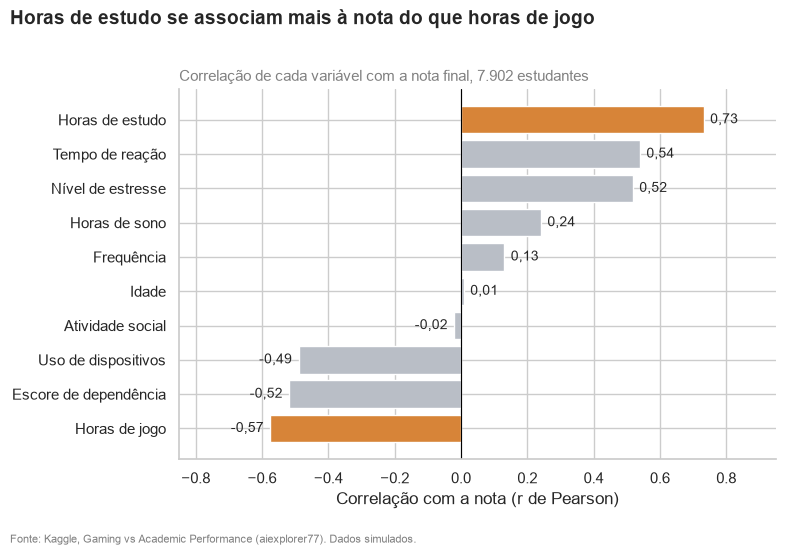

In [23]:
r = corr["grades"].drop("grades").sort_values()
cores = [DESTAQUE if v in ("study_hours", "gaming_hours") else CINZA for v in r.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([rotulos.get(v, v) for v in r.index], r.values, color=cores)
for i, v in enumerate(r.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, br(v, 2), va="center",
            ha="left" if v >= 0 else "right", fontsize=10)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.85, 0.95)
ax.set_xlabel("Correlação com a nota (r de Pearson)")
finalizar(ax, "Horas de estudo se associam mais à nota do que horas de jogo",
          f"Correlação de cada variável com a nota final, {milhar(len(df))} estudantes",
          "av1_01_correlacoes")

**Leitura:** Entre os 7.902 estudantes, as horas de estudo têm a associação mais forte com a nota (r = 0,73), acima das horas de jogo, que se associam negativamente (r = −0,57). Como a análise é correlacional, o gráfico indica associação, e não causa.

**Pergunta 2:** Como a nota acompanha as horas de jogo?

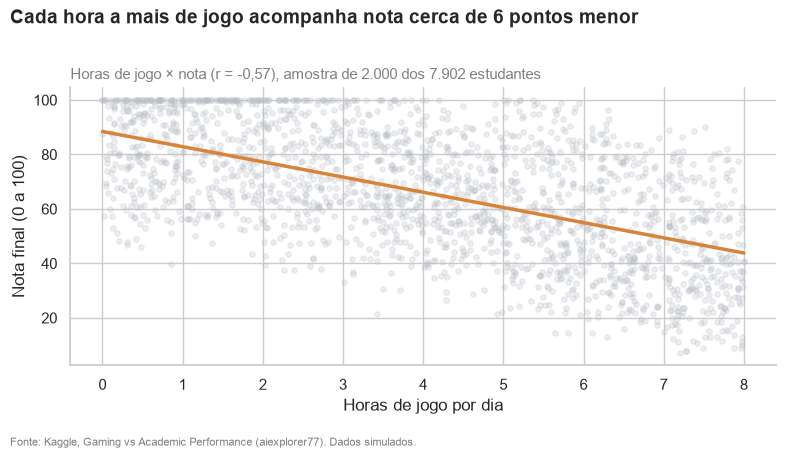

In [24]:
amostra = df.sample(2000, random_state=42)
r_jogo = df["gaming_hours"].corr(df["grades"])
coef = np.polyfit(df["gaming_hours"], df["grades"], 1)

fig, ax = plt.subplots()
ax.scatter(amostra["gaming_hours"], amostra["grades"], alpha=0.25, s=15, color=CINZA)
x = np.linspace(0, 8, 100)
ax.plot(x, np.polyval(coef, x), color=DESTAQUE, lw=2.5)
ax.set_xlabel("Horas de jogo por dia")
ax.set_ylabel("Nota final (0 a 100)")
finalizar(ax, f"Cada hora a mais de jogo acompanha nota cerca de {abs(coef[0]):.0f} pontos menor",
          f"Horas de jogo × nota (r = {br(r_jogo, 2)}), amostra de 2.000 dos {milhar(len(df))} estudantes",
          "av1_02_jogo_nota")

**Leitura:** A nota tende a diminuir conforme aumentam as horas de jogo, em uma relação aproximadamente linear, mas com grande dispersão: estudantes que jogam o mesmo tempo têm notas muito diferentes, o que indica que outros fatores também pesam.

**Pergunta 3:** A nota é diferente entre os níveis de estresse?

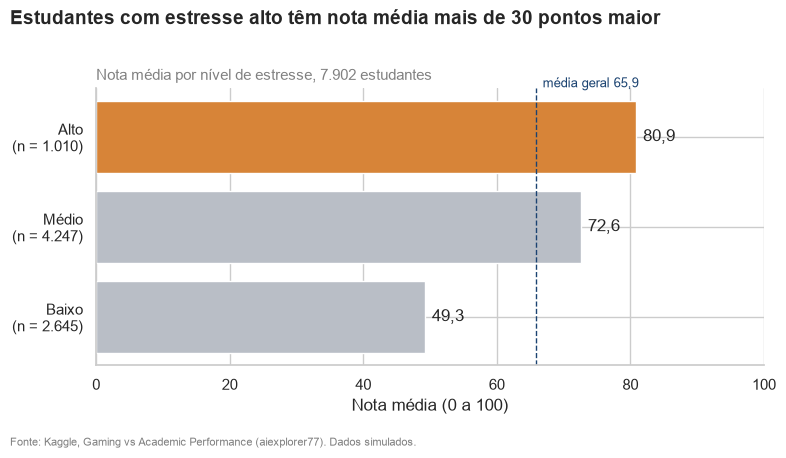

In [25]:
ordem = ["Low", "Medium", "High"]
nomes = {"Low": "Baixo", "Medium": "Médio", "High": "Alto"}
res = df.groupby("stress_level")["grades"].agg(n="size", media="mean").reindex(ordem)
media_geral = df["grades"].mean()

fig, ax = plt.subplots()
rot = [f"{nomes[s]}\n(n = {milhar(n)})" for s, n in res["n"].items()]
ax.barh(rot, res["media"], color=[DESTAQUE if s == "High" else CINZA for s in res.index])
for i, m in enumerate(res["media"]):
    ax.text(m + 1, i, br(m), va="center")
ax.axvline(media_geral, ls="--", lw=1, color="#1B4371")
ax.text(media_geral + 1, len(res) - 0.45, f"média geral {br(media_geral)}", fontsize=9, color="#1B4371")
ax.set_xlim(0, 100)
ax.set_xlabel("Nota média (0 a 100)")
finalizar(ax, "Estudantes com estresse alto têm nota média mais de 30 pontos maior",
          f"Nota média por nível de estresse, {milhar(len(df))} estudantes",
          "av1_03_nota_estresse")

**Leitura:** A nota média é de 80,9 entre os estudantes com estresse alto, contra 49,3 entre os de estresse baixo. O resultado é contraintuitivo e pode estar ligado a outras variáveis, como as horas de estudo, o que será investigado na etapa de regressão. O grupo de estresse alto é o menor (n = 1.010).

**Pergunta 4:** Quanto a preparação alterou a base?

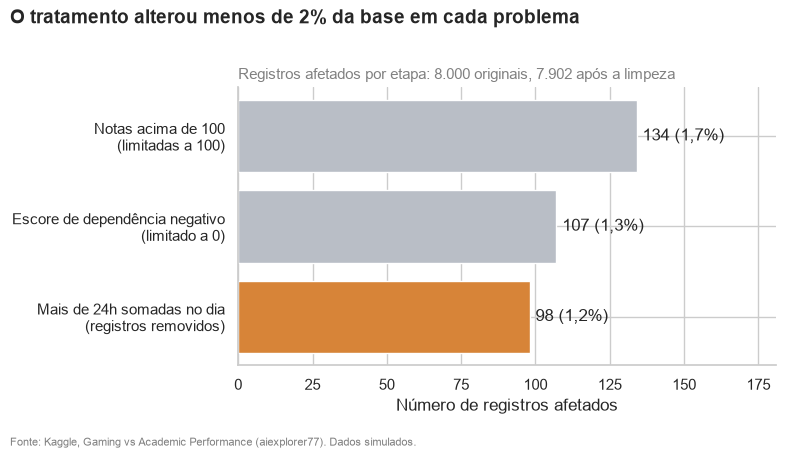

In [26]:
etapas = ["Notas acima de 100\n(limitadas a 100)",
          "Escore de dependência negativo\n(limitado a 0)",
          "Mais de 24h somadas no dia\n(registros removidos)"]
valores = [n_acima, n_neg, n_24h]
total = len(df_original)

fig, ax = plt.subplots()
ax.barh(etapas, valores, color=[CINZA, CINZA, DESTAQUE])
for i, v in enumerate(valores):
    ax.text(v + 2, i, f"{v} ({br(v / total * 100)}%)", va="center")
ax.set_xlim(0, max(valores) * 1.35)
ax.invert_yaxis()
ax.set_xlabel("Número de registros afetados")
finalizar(ax, "O tratamento alterou menos de 2% da base em cada problema",
          f"Registros afetados por etapa: {milhar(total)} originais, {milhar(len(df))} após a limpeza",
          "av1_04_preparacao")

**Leitura:** Três inconsistências foram tratadas, cada uma afetando menos de 2% da base. Notas e escores fora da escala foram limitados aos valores válidos, preservando os registros. Já os casos com mais de 24 horas diárias foram removidos, por não ser possível identificar qual variável estava incorreta. A base passou de 8.000 para 7.902 registros.

**Pergunta 5:** Como se distribuem as horas e a nota?

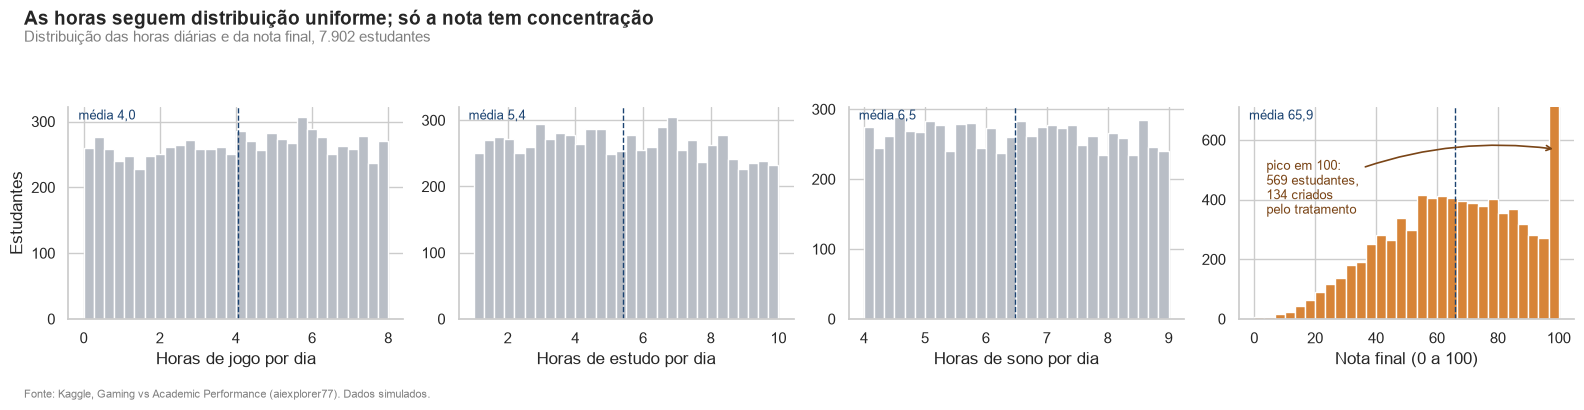

In [27]:
def finalizar_fig(fig, titulo, subtitulo, arquivo, fonte=FONTE):
    """Mesmo padrão de finalizar(), para figuras com mais de um painel."""
    fig.suptitle(titulo, x=0.02, ha="left", fontsize=14, fontweight="bold")
    fig.text(0.02, 0.90, subtitulo, fontsize=11, color="gray")
    fig.text(0.02, 0.01, fonte, fontsize=8, color="gray")
    fig.tight_layout(rect=(0, 0.04, 1, 0.88))
    fig.savefig(f"figuras/{arquivo}.png", dpi=200)
    plt.show()

painel = [("gaming_hours", "Horas de jogo por dia"), ("study_hours", "Horas de estudo por dia"),
          ("sleep_hours", "Horas de sono por dia"), ("grades", "Nota final (0 a 100)")]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (col, rotulo) in zip(axes, painel):
    cor = DESTAQUE if col == "grades" else CINZA
    ax.hist(df[col], bins=30, color=cor)
    ax.set_xlabel(rotulo)
    ax.set_ylabel("Estudantes" if col == "gaming_hours" else "")
    ax.axvline(df[col].mean(), color="#1B4371", ls="--", lw=1)
    ax.text(0.03, 0.94, f"média {br(df[col].mean())}", transform=ax.transAxes, fontsize=9, color="#1B4371")
axes[3].annotate(f"pico em 100:\n{milhar(pico_final)} estudantes,\n{viraram_100} criados\npelo tratamento",
                 xy=(99, pico_final), xytext=(4, pico_final * 0.62), fontsize=9, color="#7A4517",
                 arrowprops=dict(arrowstyle="->", color="#7A4517", lw=1.2,
                                 connectionstyle="arc3,rad=-0.15"))
axes[3].set_ylim(0, pico_final * 1.25)
finalizar_fig(fig, "As horas seguem distribuição uniforme; só a nota tem concentração",
              f"Distribuição das horas diárias e da nota final, {milhar(len(df))} estudantes",
              "av1_05_distribuicoes")

**Leitura:** Jogo, estudo e sono se espalham de forma praticamente uniforme dentro de suas faixas, sem valores
típicos e sem outliers — padrão improvável em hábitos reais e mais um indício de que a base é simulada. A nota é a
única variável com forma definida: concentra-se entre 50 e 85, com mediana 66,68, e tem um pico em 100 que reúne 569
estudantes, dos quais 134 foram colocados ali pelo nosso tratamento.

**Pergunta 6:** Quanto do pico em 100 foi criado pela preparação?

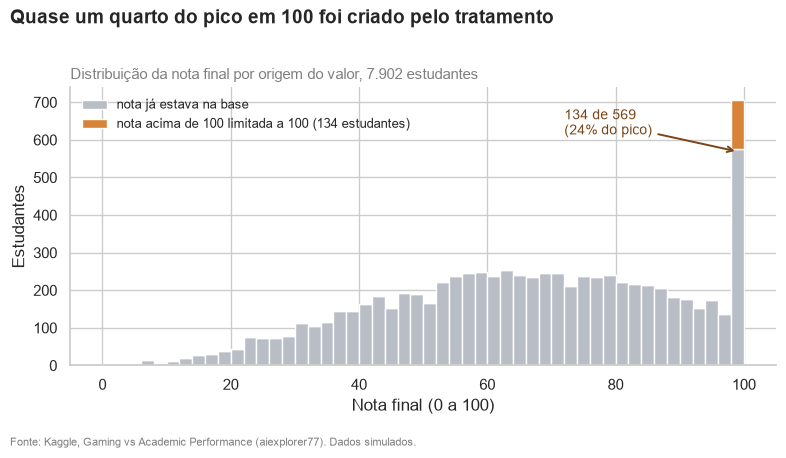

In [28]:
faixas_nota = np.arange(0, 102, 2)
nota_original = etapa2.loc[~etapa2["nota_foi_limitada"], "grades"]   # nota que o estudante já tinha
nota_limitada = etapa2.loc[etapa2["nota_foi_limitada"], "grades"]    # nota criada pelo tratamento

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist([nota_original, nota_limitada], bins=faixas_nota, stacked=True, color=[CINZA, DESTAQUE],
        label=["nota já estava na base", f"nota acima de 100 limitada a 100 ({viraram_100} estudantes)"])
ax.set_xlabel("Nota final (0 a 100)")
ax.set_ylabel("Estudantes")
ax.set_ylim(0, pico_final * 1.3)
ax.legend(loc="upper left", fontsize=9, frameon=False)
ax.annotate(f"{viraram_100} de {milhar(pico_final)}\n({viraram_100 / pico_final:.0%} do pico)",
            xy=(99, pico_final), xytext=(72, pico_final * 1.08), fontsize=10, color="#7A4517",
            arrowprops=dict(arrowstyle="->", color="#7A4517", lw=1.4))
finalizar(ax, "Quase um quarto do pico em 100 foi criado pelo tratamento",
          f"Distribuição da nota final por origem do valor, {milhar(len(df))} estudantes",
          "av1_06_pico_100")

**Leitura:** Dos 569 estudantes com nota máxima, 435 já tinham 100 na base original e 134 chegaram lá porque
limitamos as notas acima de 100 — 23,6% do pico. O efeito teto é real, mas está superestimado se a decisão de limpeza
não for considerada. A análise de sensibilidade da seção 6.3 mostra que remover esses 134 registros, em vez de
limitá-los, não altera nenhuma conclusão do trabalho.

**Pergunta 7:** Quais associações resistem ao controle por horas de jogo e de estudo?

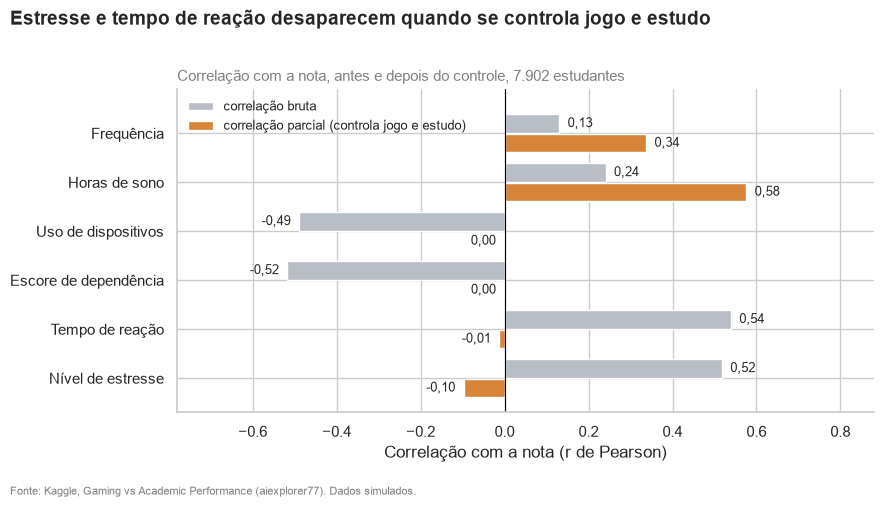

In [29]:
ordem_vis = ["stress_level_ord", "reaction_time_ms", "addiction_score", "device_usage", "sleep_hours", "attendance"]
p = parciais.loc[ordem_vis]
y = np.arange(len(p))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y + 0.2, p["r bruto"], height=0.38, color=CINZA, label="correlação bruta")
ax.barh(y - 0.2, p["r parcial"], height=0.38, color=DESTAQUE, label="correlação parcial (controla jogo e estudo)")
zero = lambda v: v if abs(v) >= 0.005 else 0.0      # evita imprimir "-0,00"
for i, (b, pa) in enumerate(zip(p["r bruto"], p["r parcial"])):
    ax.text(b + (0.02 if b >= 0 else -0.02), i + 0.2, br(zero(b), 2), va="center", ha="left" if b >= 0 else "right", fontsize=9)
    ax.text(pa + (0.02 if pa >= 0 else -0.02), i - 0.2, br(zero(pa), 2), va="center", ha="left" if pa >= 0 else "right", fontsize=9)
ax.set_yticks(y, [rotulos.get(v, v) for v in p.index])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.78, 0.88)
ax.set_ylim(-0.7, len(p) - 0.1)
ax.set_xlabel("Correlação com a nota (r de Pearson)")
ax.legend(loc="upper left", fontsize=9, frameon=False)
finalizar(ax, "Estresse e tempo de reação desaparecem quando se controla jogo e estudo",
          f"Correlação com a nota, antes e depois do controle, {milhar(len(df))} estudantes",
          "av1_07_correlacoes_parciais")

**Leitura:** O estresse cai de r = 0,52 para −0,10 e o tempo de reação, de 0,54 para −0,01: as duas associações
eram efeito das horas de jogo e de estudo, não fatores próprios. A dependência do jogo e o uso de dispositivos vão a
praticamente zero, confirmando que repetem a informação das horas de jogo. O movimento contrário acontece com o sono
(de 0,24 para 0,58) e com a frequência (de 0,13 para 0,34), que estavam encobertos pela variação muito maior de jogo e
estudo e só aparecem quando ela é descontada.

## 12. Conclusões parciais e próximas etapas

**O que os dados mostram, depois do controle por horas de jogo e de estudo:**

- O **tempo de estudo** é o fator mais associado à nota (r = 0,731), acima do tempo de jogo (r = −0,575). Juntos, os
  dois explicam **83,6%** da variação das notas. A mensagem prática continua sendo "garantir horas de estudo", e não
  apenas "proibir o jogo".
- O **sono** e a **frequência** são fatores próprios, e estavam subestimados na análise bruta: ao controlar jogo e
  estudo, a correlação do sono com a nota sobe de 0,241 para **0,576** e a da frequência, de 0,130 para **0,337**.
  São as duas únicas variáveis, além de jogo e estudo, que acrescentam poder explicativo relevante (+0,0545 e
  +0,0187 de R²).
- O **estresse não é um fator**: a correlação de +0,518 com a nota cai para **−0,098** após o controle, e o ganho de
  R² é de apenas 0,0016. O resultado contraintuitivo da análise bruta tem explicação simples — quem declara estresse
  alto estuda 8,45 h por dia, contra 4,83 h de quem declara estresse baixo. **O estresse é marcador de esforço**,
  não causa de boa nota. Essa era a principal dúvida em aberto do trabalho, e está resolvida.
- O **tempo de reação também não é um fator**: a correlação de +0,539 cai para **−0,013**. Ele tem r = −0,94 com as
  horas de jogo, ou seja, apenas mede o tempo de jogo por outro caminho.
- **Dependência do jogo e uso de dispositivos repetem as horas de jogo** (r = 0,91 e 0,85 com ela; VIF de 6,5 e 4,0).
  As correlações parciais das duas com a nota são **−0,001**, e o ganho de R² é zero. As quatro medidas de "quanto se
  joga" devem entrar na regressão **como uma só variável**, e não como quatro fatores distintos.
- Jogo e sono **não** estão correlacionados (r = −0,018), então a hipótese de mediação pelo sono não se sustenta.
- O **gênero de jogo não tem relação com a nota** (médias de 65,7 a 66,6): o que importa é quanto se joga, não o quê.

**O que o nosso próprio tratamento produziu (seção 6):**

- **23,6% do pico em 100 é artefato da limpeza:** dos 569 estudantes com nota máxima, 435 já tinham 100 e 134 foram
  criados ao limitarmos as notas acima de 100. O efeito teto é real, mas menor do que o histograma sugere.
- **A remoção dos 98 registros é seletiva:** eles tinham nota média 83,64 (contra 65,86) e eram **100% do grupo de
  estresse Low**. Removê-los baixou a média desse grupo de 50,50 para 49,27 e **amplificou em 1,2 ponto** o
  contraste entre estresse alto e baixo — justamente o achado que o controle depois desmonta.
- **Nenhuma conclusão depende dessas escolhas:** a análise de sensibilidade com quatro cenários de limpeza mostra
  variação máxima de 0,02 nas correlações principais e de 1,4 ponto na amplitude do estresse.

**Limitações:**

1. **Dados simulados.** A fonte informa que a base é sintética, o que é confirmado pelas distribuições uniformes,
   pela ausência total de outliers após a limpeza e pelas inconsistências encontradas. Como referência, a
   meta-análise de Ferguson (2015) estima a associação entre uso de videogames e desempenho acadêmico em
   r ≈ −0,01; aqui ela é de −0,575, uma ordem de grandeza completamente diferente. Os resultados valem como
   exercício analítico e **não podem ser generalizados**.
2. **Redundância entre variáveis.** Quatro das nove numéricas medem o mesmo comportamento (VIF de 4,0 a 14,4).
   A base tem menos informação independente do que o número de colunas sugere.
3. **Efeito da preparação.** Parte do pico em 100 e parte do contraste entre níveis de estresse são consequência das
   decisões de limpeza, como quantificado na seção 6.
4. **Ausência de recorte.** A fonte não informa período, país nem instituição, o que impede qualquer comparação com
   populações reais.
5. **Análise correlacional.** Mesmo com os controles por jogo e estudo, as associações observadas não estabelecem
   causalidade: outras variáveis não medidas (dificuldade das disciplinas, trabalho, condição socioeconômica) podem
   explicar os resultados.
6. **Grupos desbalanceados.** O grupo de estresse alto é o menor (n = 761 no treino dos modelos; 1.010 na base
   original), o que exige cautela nas comparações de médias.

**Próximas etapas e onde elas foram respondidas:**

A fase de Machine Learning do projeto está em dois notebooks que partem desta mesma base e reaplicam, dentro da
função `limpar`, as regras de preparação definidas aqui:

| Notebook | Pergunta | Modelo escolhido | Resultado no teste |
|---|---|---|---|
| `oficina_ML_Regressao_GrupoGamingvsAcademicPerformance.ipynb` | Quanto o estudante vai tirar de nota? | Regressão linear | MAE de **5,14 pontos**, 73% abaixo da referência (18,77) |
| `oficina_ML_Classificacao_GrupoGamingvsAcademicPerformance.ipynb` | Quem precisa entrar no programa de acompanhamento? | Árvore de decisão (profundidade 4, limiar 0,10) | Recall de **95,3%**, custo 72% abaixo da referência |

- ✅ **Comparar grupos por faixa de horas de jogo, para verificar se existe um "ponto de virada".** Não existe: a
  nota cai de forma contínua — 82,1 (até 2h), 69,5 (2h a 5h) e 52,4 (mais de 5h) — e o risco de ficar abaixo de 60
  sobe de 10,3% para 32,1% e 65,4%. O grupo realmente crítico é definido pela **combinação**: quem joga mais de 5h e
  estuda menos de 4h tem nota média de 33,5 e **98,5% de chance de ficar abaixo da nota de corte**.
- ✅ **Investigar a associação positiva do estresse e do tempo de reação com a nota.** Respondido na seção 10 deste
  notebook, pelas correlações parciais, e confirmado nos dois notebooks de ML, onde as duas variáveis recebem
  importância **zero**.
- ✅ **Testar estresse, sono e dependência como mediadores.** Com jogo e estudo no modelo, dependência, uso de
  dispositivos e tempo de reação ficam com ganho de R² nulo e importância zero nas árvores. Sobra o sono, com efeito
  próprio (+0,0545 de R² aqui; +3,46 pontos por hora na regressão linear do notebook de ML).
- ✅ **Estimar o peso relativo de cada fator na nota.** O fator mais importante não é nenhuma das variáveis
  originais, e sim uma criada a partir desta EDA: `saldo_estudo_jogo` = `study_hours` − `gaming_hours`, responsável
  por **92%** da importância na árvore de regressão e **89,8%** na de classificação. O que prevê a nota não é quanto
  o estudante joga, e sim **quanto ele estuda a mais (ou a menos) do que joga**.
- ⬜ **Elaborar as visualizações finais e a apresentação.**

**Decisão sobre aplicar o modelo: Investigar.** Os dois modelos passam em todos os critérios técnicos (sem
vazamento, superam a referência com folga, validação e teste próximos), mas a base é simulada. A justificativa
completa está na seção 9 de cada notebook de ML.